# LTE: how OFDM turns one multipath channel into hundreds of flat ones

The signal reaches the receiver along several paths with delays $\tau_l$: $r(t)=\sum_l h_l\,s(t-\tau_l)+n(t)$. In a city the delay spread is a few microseconds. With a single 5 MHz carrier, a symbol lasts 0.13 µs, so each symbol smears over dozens of neighbours. That is **inter-symbol interference (ISI)**. CDMA handled it with a RAKE receiver; here it would take an equalizer with hundreds of taps.

**The OFDM idea**: instead of one fast stream, send $N$ slow ones on orthogonal subcarriers $k\,\Delta f$. A subcarrier symbol lasts $T_u=1/\Delta f=66.7$ µs $\gg\tau_\text{max}$:
$$x[n]=\frac1{\sqrt N}\sum_{k}X_k\,e^{\,j2\pi kn/N},\qquad n=-N_\text{cp},\dots,N-1$$
This is just an IFFT. The first $N_\text{cp}$ samples are the **cyclic prefix**, a copy of the symbol's tail. As long as the channel delay $L\le N_\text{cp}$, linear convolution with $h$ over the FFT window equals **circular** convolution, and circular convolution in the Fourier basis is multiplication:
$$Y_k=H_k\,X_k+W_k,\qquad H_k=\sum_l h_l\,e^{-j2\pi kl/N}$$
A wideband channel with memory has become $N$ independent flat channels, and the equalizer is **one complex division per subcarrier**. The price: the CP carries no data (7 % of the time), and some subcarriers fall into fades. A code spread across frequency fixes that.

**LTE numerology** (36.211): $\Delta f=15$ kHz, a 0.5 ms slot = 7 OFDM symbols, a 1 ms subframe, a resource block (RB) = 12 subcarriers × 1 slot = 180 kHz. $f_s=N\Delta f$, so the CP length scales with bandwidth in samples but not in time:

| Bandwidth | 1.4 | 3 | 5 | 10 | 20 MHz |
|---|---|---|---|---|---|
| $N_\text{FFT}$ | 128 | 256 | 512 | 1024 | 2048 |
| RBs / subcarriers | 6 / 72 | 15 / 180 | 25 / 300 | 50 / 600 | 100 / 1200 |
| $f_s$, MHz | 1.92 | 3.84 | 7.68 | 15.36 | 30.72 |

Normal CP: 5.2 µs for the first symbol of a slot, 4.7 µs for the rest; extended CP: 16.7 µs (6 symbols per slot).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import erfc, j0
from scipy.integrate import quad
from scipy.optimize import brentq
from scipy.signal import welch

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

SEED = 1
BW_MHZ = 5          # 1.4 / 3 / 5 / 10 / 20
PROFILE = "EVA"     # EPA (pedestrian) / EVA (vehicular) / ETU (urban): 3GPP 36.104 models
SNR_DB = 20         # SNR per resource element for sections 4–5
FC_GHZ = 2.0        # carrier frequency (Doppler)
SPEED_KMH = 120
K_TURBO = 1024      # turbo code block length (QPP available for 40, 512, 1024, 2048, 6144)
TURBO_ITERS = 8
CELL_ID = 0

rng = np.random.default_rng(SEED)

## Primitives: OFDM, 3GPP channels, QAM, CRS, turbo code

In [2]:
# ---------- numerology ----------
DF = 15e3
NUM = {1.4: (128, 6), 3: (256, 15), 5: (512, 25), 10: (1024, 50), 20: (2048, 100)}
N_FFT, N_RB = NUM[BW_MHZ]
FS = N_FFT * DF
N_SC = 12 * N_RB
T_U = 1 / DF
CP = np.array([160] + [144] * 6) * N_FFT // 2048            # normal CP, 7 symbols per slot
CP_EXT = 512 * N_FFT // 2048                                 # extended CP
SC_IDX = np.r_[-N_SC // 2:0, 1:N_SC // 2 + 1]                # occupied subcarriers, DC left empty

def sym_starts(nsym, cp=CP):
    """Index where the useful part (after the CP) of each symbol starts."""
    cps = np.array([cp[s % len(cp)] for s in range(nsym)])
    return np.cumsum(np.r_[0, cps[:-1] + N_FFT]) + cps

def ofdm_mod(X, cp=None):
    """X (..., Nsym, N_SC) → samples (..., L). cp: CP lengths (cycled over symbols). Unit power per subcarrier."""
    cp = CP if cp is None else np.atleast_1d(cp)
    G = np.zeros(X.shape[:-1] + (N_FFT,), complex)
    G[..., SC_IDX % N_FFT] = X
    x = np.fft.ifft(G, axis=-1) * np.sqrt(N_FFT)
    return np.concatenate([np.concatenate([x[..., s, N_FFT - cp[s % len(cp)]:], x[..., s, :]], -1)
                           for s in range(X.shape[-2])], -1)

def ofdm_demod(y, nsym, cp=None):
    cp = CP if cp is None else np.atleast_1d(cp)
    st = sym_starts(nsym, cp)
    seg = np.stack([y[..., p:p + N_FFT] for p in st], -2)
    return np.fft.fft(seg, axis=-1)[..., SC_IDX % N_FFT] / np.sqrt(N_FFT)

# ---------- 3GPP 36.104 channels (delays in ns, powers in dB) ----------
PROFILES = {
    "EPA": ([0, 30, 70, 90, 110, 190, 410], [0, -1, -2, -3, -8, -17.2, -20.8]),
    "EVA": ([0, 30, 150, 310, 370, 710, 1090, 1730, 2510], [0, -1.5, -1.4, -3.6, -0.6, -9.1, -7, -12, -16.9]),
    "ETU": ([0, 50, 120, 200, 230, 500, 1600, 2300, 5000], [-1, -1, -1, 0, 0, 0, -3, -5, -7]),
}

def pdp(name):
    t, p = PROFILES[name]
    p = 10 ** (np.array(p) / 10)
    return np.array(t) * 1e-9, p / p.sum()

def tau_rms(name):
    t, p = pdp(name)
    return np.sqrt((p * t**2).sum() - (p * t).sum()**2)

def tap_delays(name):
    """Path delays rounded to the nearest sample."""
    return np.round(pdp(name)[0] * FS).astype(int)

def fading(name, n_samp, fd, rng, batch=(), n_sin=16):
    """Rayleigh multipath channel: path gains g (*batch, n_samp, P); delays come from tap_delays(name).
    Each path follows the Jakes model (n_sin waves with uniform arrival angles), fd is the max Doppler in Hz; fd = 0 is static."""
    p = pdp(name)[1]
    tt = np.arange(n_samp) / FS
    g = np.empty(batch + (n_samp, len(p)), complex)
    for k in range(len(p)):
        if fd == 0:
            gk = (rng.standard_normal(batch + (1,)) + 1j * rng.standard_normal(batch + (1,))) / np.sqrt(2)
        else:
            al = 2 * np.pi * (np.arange(n_sin) + rng.random(batch + (n_sin,))) / n_sin
            ph = rng.uniform(0, 2 * np.pi, batch + (n_sin,))
            gk = np.exp(1j * (2 * np.pi * fd * np.cos(al)[..., None] * tt + ph[..., None])).sum(-2) / np.sqrt(n_sin)
        g[..., k] = np.sqrt(p[k]) * gk
    return g

def apply_channel(x, g, d):
    """y[n] = Σ_k g[n,k]·x[n − d_k]; g is (..., n, P), or (..., 1, P) for a static channel."""
    y = np.zeros(x.shape, complex); n = x.shape[-1]
    for k, dk in enumerate(d):
        gk = np.broadcast_to(g[..., k], x.shape)
        y[..., dk:] += gk[..., dk:] * x[..., :n - dk]
    return y

def freq_response(g, d):
    """H_k = Σ_l g_l·exp(−j2πk d_l/N) on the occupied subcarriers: g (..., P) → (..., N_SC)"""
    return g @ np.exp(-2j * np.pi * np.outer(d, SC_IDX) / N_FFT)

def awgn(shape, n0, rng):
    return np.sqrt(n0 / 2) * (rng.standard_normal(shape) + 1j * rng.standard_normal(shape))

# ---------- QAM with the 36.211 Gray mapping ----------
class QAM:
    """Q = 2/4/6 bits. Bits alternate I,Q: b0,b1 are signs; b2,b3 and b4,b5 are Gray-coded amplitudes. Unit average power."""
    LV = {1: {(): 1}, 2: {(0,): 1, (1,): 3}, 3: {(0, 0): 3, (0, 1): 1, (1, 0): 5, (1, 1): 7}}
    def __init__(self, Q):
        self.Q, self.m = Q, Q // 2
        self.ax_bits = ((np.arange(2**self.m)[:, None] >> np.arange(self.m)[::-1]) & 1)
        self.amp = np.array([(1 - 2 * b[0]) * self.LV[self.m][tuple(b[1:])] for b in self.ax_bits], float)
        self.amp /= np.sqrt(2 * (self.amp**2).mean())
        nI = len(self.amp)
        self.const = (self.amp[:, None] + 1j * self.amp[None, :]).ravel()
        B = np.empty((nI * nI, Q), int)
        B[:, 0::2] = np.repeat(self.ax_bits, nI, 0); B[:, 1::2] = np.tile(self.ax_bits, (nI, 1))
        self.cbits, self.w = B, 2 ** np.arange(Q)[::-1]
        self.idx_of = np.zeros(2**Q, int); self.idx_of[B @ self.w] = np.arange(nI * nI)
    def mod(self, b):
        return self.const[self.idx_of[b.reshape(b.shape[:-1] + (-1, self.Q)) @ self.w]]
    def llr(self, z, n0):
        """max-log LLR = ln P(0)/P(1) for equalized z with effective noise n0 (element-wise)."""
        L = np.empty(z.shape + (self.Q,))
        for ax, comp in ((0, z.real), (1, z.imag)):
            d = (comp[..., None] - self.amp) ** 2 / (np.broadcast_to(n0, z.shape)[..., None] / 2)
            for j in range(self.m):
                b = self.ax_bits[:, j]
                L[..., 2 * j + ax] = 0.5 * (d[..., b == 1].min(-1) - d[..., b == 0].min(-1))
        return L.reshape(z.shape[:-1] + (-1,))
    def hard(self, z):
        return self.cbits[np.abs(z[..., None] - self.const).argmin(-1)].reshape(z.shape[:-1] + (-1,))

def _qam_ab(Q):
    """BER ≈ a·erfc(√(b·Es/N0)): exact for QPSK, nearest-neighbour (Gray) for 16/64QAM."""
    M = 2**Q
    return (0.5, 0.5) if Q == 2 else ((2 / Q) * (1 - 1 / np.sqrt(M)), 3 / (2 * (M - 1)))

def ber_awgn(Q, esn0):
    a, b = _qam_ab(Q)
    return a * erfc(np.sqrt(b * np.asarray(esn0)))

def ber_rayleigh(Q, esn0_mean):
    """The same, averaged over an exponential SNR: E[erfc(√(bγ))] = 1 − √(bγ̄/(1+bγ̄))."""
    a, b = _qam_ab(Q); bg = b * np.asarray(esn0_mean)
    return a * (1 - np.sqrt(bg / (1 + bg)))

# ---------- CRS: length-31 Gold sequence (36.211 §7.2, §6.10.1) ----------
def gold_c(c_init, n, Nc=1600):
    x1 = np.zeros(Nc + n + 31, np.uint8); x2 = np.zeros_like(x1)
    x1[0] = 1; x2[:31] = (c_init >> np.arange(31)) & 1
    for i in range(Nc + n):
        x1[i + 31] = x1[i + 3] ^ x1[i]
        x2[i + 31] = x2[i + 3] ^ x2[i + 2] ^ x2[i + 1] ^ x2[i]
    return x1[Nc:Nc + n] ^ x2[Nc:Nc + n]

def crs_grid(n_sym=14, cell_id=CELL_ID, n_rb_max=110):
    """Mask and values of the port-0 CRS: slot symbols l=0 and l=4, every 6th subcarrier, offset 3, and v_shift = cell_id mod 6."""
    M = np.zeros((n_sym, N_SC), bool); V = np.zeros((n_sym, N_SC), complex)
    vs = cell_id % 6
    for s in range(n_sym):
        ns, l = (s // 7) % 20, s % 7
        if l not in (0, 4):
            continue
        c = gold_c(2**10 * (7 * (ns + 1) + l + 1) * (2 * cell_id + 1) + 2 * cell_id + 1, 4 * n_rb_max)
        r = ((1 - 2.0 * c[0::2]) + 1j * (1 - 2.0 * c[1::2])) / np.sqrt(2)
        m = np.arange(2 * N_RB)
        k = 6 * m + ((0 if l == 0 else 3) + vs) % 6
        M[s, k] = True; V[s, k] = r[m + n_rb_max - N_RB]
    return M, V

def chan_est(Y, Xp, mask, time_mode="linear"):
    """LS at the pilots → linear interpolation in frequency → in time ('linear' between pilot symbols, or 'hold')."""
    psyms = np.nonzero(mask.any(1))[0]; k = np.arange(N_SC)
    Hp = []
    for s in psyms:
        kk = np.nonzero(mask[s])[0]
        ls = Y[..., s, kk] / Xp[s, kk]
        f = lambda v: np.interp(k, kk, v)
        Hp.append(np.apply_along_axis(f, -1, ls.real) + 1j * np.apply_along_axis(f, -1, ls.imag))
    Hp = np.stack(Hp, -2)
    nsym = Y.shape[-2]
    if time_mode == "hold":
        return Hp[..., np.maximum(np.searchsorted(psyms, np.arange(nsym), "right") - 1, 0), :]
    j = np.clip(np.searchsorted(psyms, np.arange(nsym)), 1, len(psyms) - 1)
    w = ((np.arange(nsym) - psyms[j - 1]) / (psyms[j] - psyms[j - 1]))[:, None]
    w = np.minimum(w, 1.0)                                   # after the last pilot: hold
    return (1 - w) * Hp[..., j - 1, :] + w * Hp[..., j, :]

# ---------- LTE turbo code (36.212 §5.1.3) ----------
QPP = {40: (3, 10), 512: (31, 64), 1024: (31, 64), 2048: (31, 64), 6144: (263, 480)}

def qpp(K):
    """Quadratic permutation polynomial interleaver Π(i) = (f1·i + f2·i²) mod K."""
    f1, f2 = QPP[K]
    i = np.arange(K, dtype=np.int64)
    return (f1 * i + f2 * i * i) % K

# RSC: G(D) = [1, g1/g0], g0 = 1+D²+D³ (13₈) is the feedback, g1 = 1+D+D³ (15₈); 8 states
NXT = np.zeros((8, 2), int); PAR = np.zeros((8, 2), int); FB = np.zeros(8, int)
for s in range(8):
    s1, s2, s3 = (s >> 2) & 1, (s >> 1) & 1, s & 1
    FB[s] = s2 ^ s3                                           # input that cancels the feedback → tail bits
    for u in (0, 1):
        a = u ^ s2 ^ s3
        NXT[s, u] = (a << 2) | (s1 << 1) | s2
        PAR[s, u] = a ^ s1 ^ s3
PREV_S = np.zeros((8, 2), int); PREV_U = np.zeros((8, 2), int)
_c = np.zeros(8, int)
for s in range(8):
    for u in (0, 1):
        ns = NXT[s, u]; PREV_S[ns, _c[ns]] = s; PREV_U[ns, _c[ns]] = u; _c[ns] += 1

def rsc_encode(u):
    B, K = u.shape
    s = np.zeros(B, int); z = np.empty((B, K), int)
    for k in range(K):
        z[:, k] = PAR[s, u[:, k]]; s = NXT[s, u[:, k]]
    xt = np.empty((B, 3), int); zt = np.empty((B, 3), int)
    for k in range(3):                                        # terminate in the zero state
        ut = FB[s]; xt[:, k] = ut; zt[:, k] = PAR[s, ut]; s = NXT[s, ut]
    return z, xt, zt

def turbo_encode(u):
    """u (B,K) → (B, 3K+12): triples [systematic, parity 1, parity 2] and 12 tail bits. R ≈ 1/3."""
    z1, xt1, zt1 = rsc_encode(u)
    z2, xt2, zt2 = rsc_encode(u[:, qpp(u.shape[1])])
    return np.concatenate([np.stack([u, z1, z2], -1).reshape(len(u), -1), xt1, zt1, xt2, zt2], 1)

def _maxstar(a, b, exact):
    m = np.maximum(a, b)
    return m + np.log1p(np.exp(-np.abs(a - b))) if exact else m

def bcjr(Ls, Lp, La, Lst, Lpt, exact):
    """MAP decoder for the RSC (log-MAP or max-log-MAP) on a terminated trellis. Inputs/outputs are LLRs ln P(0)/P(1), (B,K)."""
    B, K = Ls.shape
    Lx = np.concatenate([Ls + La, Lst], 1).T; Lz = np.concatenate([Lp, Lpt], 1).T
    zs = 1 - 2 * PAR; xs = np.array([1, -1])
    g = 0.5 * (Lx[:, :, None, None] * xs + Lz[:, :, None, None] * zs)     # γ_t(s,u): (T,B,8,2)
    T = K + 3
    al = np.full((T + 1, B, 8), -1e9); al[0, :, 0] = 0
    for t in range(T):
        a = _maxstar(al[t][:, PREV_S[:, 0]] + g[t][:, PREV_S[:, 0], PREV_U[:, 0]],
                     al[t][:, PREV_S[:, 1]] + g[t][:, PREV_S[:, 1], PREV_U[:, 1]], exact)
        al[t + 1] = a - a.max(1, keepdims=True)
    be = np.full((B, 8), -1e9); be[:, 0] = 0
    Lout = np.empty((B, K))
    for t in range(T - 1, -1, -1):
        m = al[t][:, :, None] + g[t] + be[:, NXT]
        if t < K:
            red = (lambda v: np.logaddexp.reduce(v, 1)) if exact else (lambda v: v.max(1))
            Lout[:, t] = red(m[:, :, 0]) - red(m[:, :, 1])
        b = _maxstar(be[:, NXT[:, 0]] + g[t][:, :, 0], be[:, NXT[:, 1]] + g[t][:, :, 1], exact)
        be = b - b.max(1, keepdims=True)
    return Lout

def turbo_decode(L, K, iters=TURBO_ITERS, exact=True, scale=0.7, cb=None):
    """Iterative decoder: two BCJRs exchange extrinsic information through the QPP interleaver.
    With max-log, the extrinsic LLRs are multiplied by scale (compensates overconfidence, like α in min-sum)."""
    m = L[:, :3 * K].reshape(-1, K, 3); t = L[:, 3 * K:]
    Ls, Lp1, Lp2 = m[..., 0], m[..., 1], m[..., 2]
    pi = qpp(K); ipi = np.argsort(pi)
    sc = 1.0 if exact else scale
    La = np.zeros_like(Ls)
    for it in range(iters):
        L1 = bcjr(Ls, Lp1, La, t[:, 0:3], t[:, 3:6], exact)
        Le1 = sc * (L1 - Ls - La)
        L2 = bcjr(Ls[:, pi], Lp2, Le1[:, pi], t[:, 6:9], t[:, 9:12], exact)
        La = (sc * (L2 - Ls[:, pi] - Le1[:, pi]))[:, ipi]
        if cb: cb(it, L2[:, ipi])
    return (L2[:, ipi] < 0).astype(int)

def puncture_half(K):
    """Mask for R≈1/2: every other parity bit of each encoder is punctured (real LTE rate matching does this through a circular buffer)."""
    m = np.ones((K, 3), bool); m[1::2, 1] = False; m[0::2, 2] = False
    return np.r_[m.ravel(), np.ones(12, bool)]

# self-checks
assert all(len(np.unique(qpp(K))) == K for K in QPP), "QPP is not a permutation"
_u = rng.integers(0, 2, (4, 40)); _c = turbo_encode(_u)
assert np.all(turbo_decode(4.0 * (1 - 2 * _c), 40) == _u)
for Q in (2, 4, 6):
    _b = rng.integers(0, 2, (3, 60 * Q)); assert np.all(QAM(Q).hard(QAM(Q).mod(_b)) == _b)
_X = QAM(2).mod(rng.integers(0, 2, (14, 2 * N_SC)))
print(f"BW {BW_MHZ} MHz: N_FFT = {N_FFT}, {N_RB} RBs = {N_SC} subcarriers, f_s = {FS/1e6:.2f} MHz, "
      f"sample {1e9/FS:.0f} ns")
print(f"CP: {CP[0]}/{CP[1]} samples = {CP[0]/FS*1e6:.2f}/{CP[1]/FS*1e6:.2f} µs, extended {CP_EXT} = {CP_EXT/FS*1e6:.1f} µs; "
      f"subframe = {len(ofdm_mod(_X))} samples = {len(ofdm_mod(_X))/FS*1e3:.3f} ms")
print("OFDM without a channel: max|Y − X| =", f"{np.abs(ofdm_demod(ofdm_mod(_X), 14) - _X).max():.1e}")

BW 5 MHz: N_FFT = 512, 25 RBs = 300 subcarriers, f_s = 7.68 MHz, sample 130 ns
CP: 40/36 samples = 5.21/4.69 µs, extended 128 = 16.7 µs; subframe = 7680 samples = 1.000 ms
OFDM without a channel: max|Y − X| = 7.4e-16


## 1. The multipath channel in time and in frequency
Left: the 3GPP delay profiles. The dashed line is the normal CP. EPA and EVA fit with a large margin; ETU's last path (5 µs) sticks out slightly. Right: $|H(f)|$ of one realization across the whole band. The larger the delay spread $\tau_\text{rms}$, the more often the channel fades in frequency. The coherence bandwidth $B_c\approx1/(5\tau_\text{rms})$ is the scale over which the channel is "roughly flat". A 15 kHz subcarrier is much narrower than $B_c$ for every profile, so on one subcarrier the channel is a single complex number.

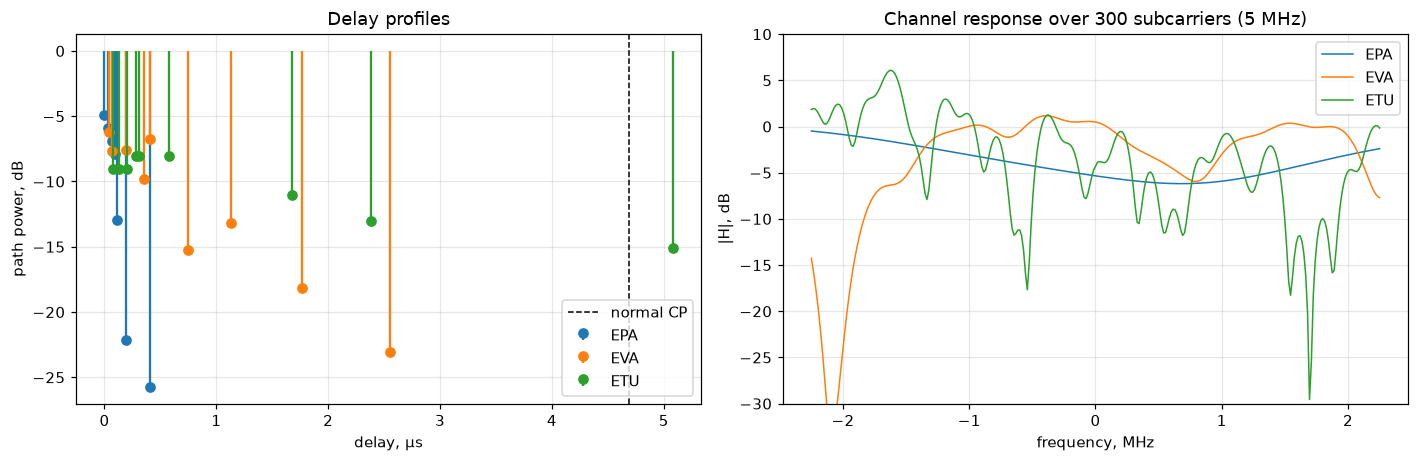

     | τ_max, µs | τ_rms, ns | B_c, kHz | B_c/Δf | τ_max in samples of a single 7.68 MHz carrier
EPA  |      0.41  |       43  |    4637  | 309.1  | 3
EVA  |      2.51  |      357  |     561  |  37.4  | 19
ETU  |      5.00  |      991  |     202  |  13.5  | 38


In [3]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.3))
f_sc = SC_IDX * DF / 1e6
rows = []
for i, name in enumerate(PROFILES):
    t, p = pdp(name)
    ax[0].stem(t * 1e6 + 0.04 * i, 10 * np.log10(p), linefmt=f"C{i}-", markerfmt=f"C{i}o", basefmt=" ", label=name)
    g = fading(name, 1, 0, np.random.default_rng(10 + i))[0]
    ax[1].plot(f_sc, 20 * np.log10(np.abs(freq_response(g, tap_delays(name)))), f"C{i}", lw=1, label=name)
    tr = tau_rms(name)
    rows.append((name, t.max() * 1e6, tr * 1e9, 1 / (5 * tr) / 1e3, t.max() * FS))
ax[0].axvline(CP[1] / FS * 1e6, color="k", ls="--", lw=1, label="normal CP")
ax[0].set_xlabel("delay, µs"); ax[0].set_ylabel("path power, dB"); ax[0].legend(); ax[0].set_title("Delay profiles")
ax[1].set_xlabel("frequency, MHz"); ax[1].set_ylabel("|H|, dB"); ax[1].set_ylim(-30, 10); ax[1].legend()
ax[1].set_title(f"Channel response over {N_SC} subcarriers ({BW_MHZ} MHz)")
plt.tight_layout(); plt.show()

print(f"{'':4} | τ_max, µs | τ_rms, ns | B_c, kHz | B_c/Δf | τ_max in samples of a single {FS/1e6:.2f} MHz carrier")
for name, tm, tr, bc, ns in rows:
    print(f"{name:4} | {tm:9.2f}  | {tr:8.0f}  | {bc:7.0f}  | {bc*1e3/DF:5.1f}  | {ns:.0f}")

## 2. The OFDM symbol
Left: the spectrum of each subcarrier over the interval $T_u$ is $\operatorname{sinc}\big((f-k\Delta f)/\Delta f\big)$. The spectra overlap heavily, but at $k\Delta f$ every neighbour passes through zero. That is orthogonality, and the FFT samples exactly at those points.

Centre: one symbol in time (real part) with its CP. The first $N_\text{cp}$ samples repeat the last ones exactly. Right: the spectrum of a subframe. $N_\text{SC}\cdot\Delta f$ is occupied, the rest up to $f_s$ is guard band, and the DC subcarrier in the middle is left empty (so local-oscillator leakage in a direct-conversion receiver doesn't corrupt data).

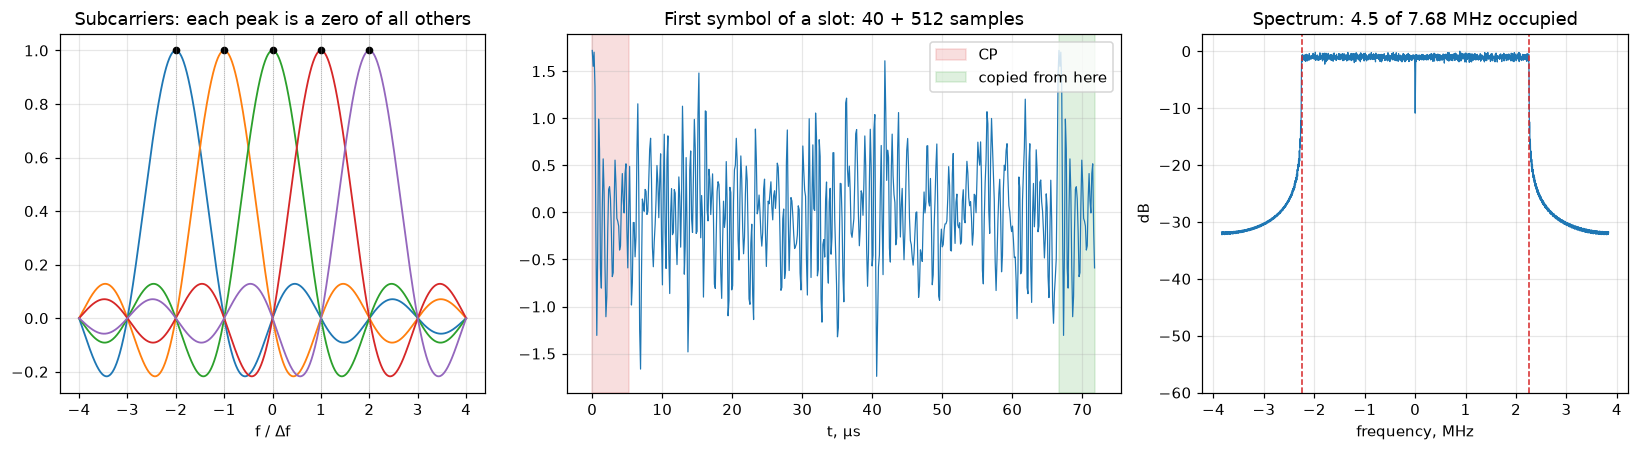

CP = copy of the tail: max|x[0:40] − x[512:552]| = 0.0e+00
CP overhead: 6.7% of the time


In [4]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2), gridspec_kw={"width_ratios": [1, 1.3, 1]})
f = np.linspace(-4, 4, 1000)
for k in range(-2, 3):
    ax[0].plot(f, np.sinc(f - k), lw=1.2)
    ax[0].plot(k, 1, "ko", ms=4)
ax[0].set_xlabel("f / Δf"); ax[0].set_title("Subcarriers: each peak is a zero of all others")
for k in range(-2, 3):
    ax[0].axvline(k, color="0.6", lw=0.5, ls=":")

q16 = QAM(4)
X = q16.mod(rng.integers(0, 2, (1, 14, 4 * N_SC)))
x = ofdm_mod(X)[0]
n1 = CP[0] + N_FFT
tt = np.arange(n1) / FS * 1e6
ax[1].plot(tt, x[:n1].real, "C0", lw=0.8)
ax[1].axvspan(0, CP[0] / FS * 1e6, color="C3", alpha=0.15, label="CP")
ax[1].axvspan(N_FFT / FS * 1e6, n1 / FS * 1e6, color="C2", alpha=0.15, label="copied from here")
ax[1].set_xlabel("t, µs"); ax[1].legend(loc="upper right"); ax[1].set_title(f"First symbol of a slot: {CP[0]} + {N_FFT} samples")

X = q16.mod(rng.integers(0, 2, (40, 14, 4 * N_SC)))
fw, P = welch(ofdm_mod(X).ravel(), FS, nperseg=2048, return_onesided=False)
o = np.argsort(fw)
ax[2].plot(fw[o] / 1e6, 10 * np.log10(P[o] / P.max()), lw=0.8)
for e in (-1, 1):
    ax[2].axvline(e * N_SC * DF / 2e6, color="C3", ls="--", lw=1)
ax[2].set_xlabel("frequency, MHz"); ax[2].set_ylabel("dB"); ax[2].set_ylim(-60, 3)
ax[2].set_title(f"Spectrum: {N_SC*DF/1e6:.1f} of {FS/1e6:.2f} MHz occupied")
plt.tight_layout(); plt.show()
print(f"CP = copy of the tail: max|x[0:{CP[0]}] − x[{N_FFT}:{n1}]| = {np.abs(ofdm_mod(X[:1])[0, :CP[0]] - ofdm_mod(X[:1])[0, N_FFT:n1]).max():.1e}")
print(f"CP overhead: {CP.sum() / (CP.sum() + 7 * N_FFT):.1%} of the time")

## 3. Why the CP matters: interference with a short prefix
A path delayed by $d_l$ samples, with $d_l>N_\text{cp}$, drags $d_l-N_\text{cp}$ samples of the **previous** symbol into the FFT window (ISI) and loses as many samples of the current one. The convolution is no longer circular and subcarriers start leaking into each other (ICI). With independent data both terms are noise-like, and the interference power is
$$P_\text{I}\approx\frac{2}{N}\sum_l p_l\,(d_l-N_\text{cp})^+$$
Below: no noise, perfect knowledge of $H_k$. Whatever remains after the equalizer is interference caused by the channel. Right: 16QAM through ETU without a CP and with an extended CP.

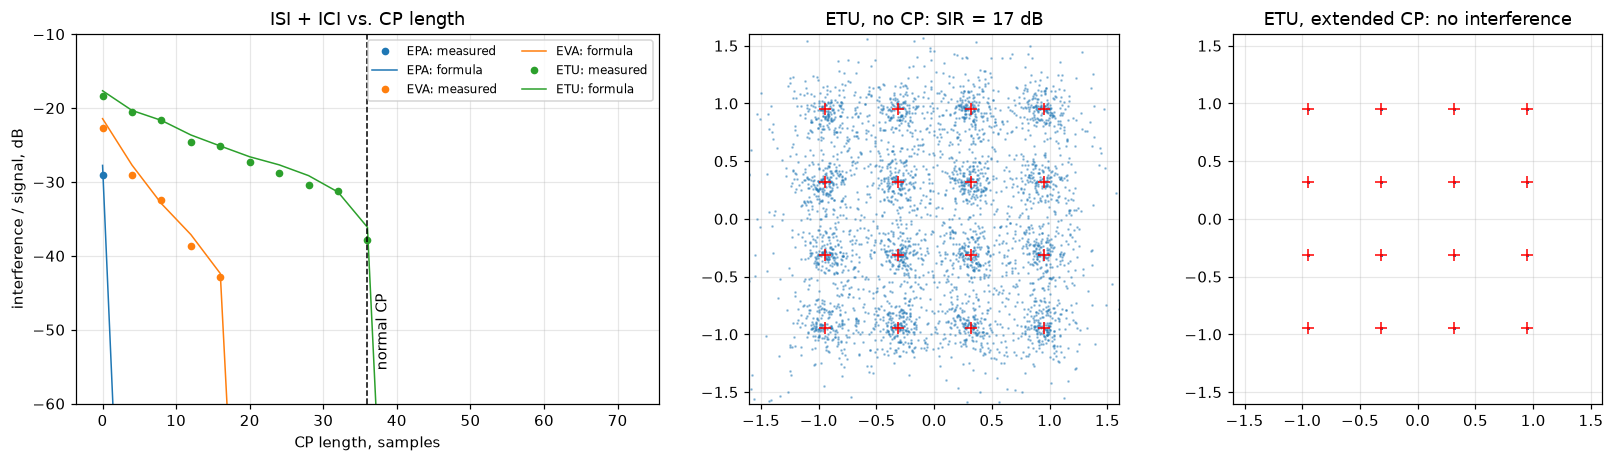

ETU: last path at 38.4 samples with CP = 36 → interference -36 dB, below the noise in any realistic scenario; the extended CP (16.7 µs) is for large cells and MBSFN


In [5]:
B, nsym = 40, 14
cps = np.arange(0, 73, 4)
fig, ax = plt.subplots(1, 3, figsize=(15, 4.3), gridspec_kw={"width_ratios": [1.4, 1, 1]})
for i, name in enumerate(PROFILES):
    p = pdp(name)[1]; d = tap_delays(name)
    meas, th = [], []
    for c in cps:
        X = q16.mod(rng.integers(0, 2, (B, nsym, 4 * N_SC)))
        g = fading(name, 1, 0, rng, (B,))
        Y = ofdm_demod(apply_channel(ofdm_mod(X, [c]), g, d), nsym, [c])
        e = Y[:, 1:] - freq_response(g, d) * X[:, 1:]
        meas.append(np.mean(np.abs(e)**2)); th.append(2 * np.sum(p * np.clip(d - c, 0, None)) / N_FFT)
    ax[0].plot(cps, 10 * np.log10(np.maximum(meas, 1e-12)), f"C{i}o", ms=4, label=f"{name}: measured")
    ax[0].plot(cps, 10 * np.log10(np.maximum(th, 1e-12)), f"C{i}-", lw=1, label=f"{name}: formula")
ax[0].axvline(CP[1], color="k", ls="--", lw=1); ax[0].text(CP[1] + 1, -55, "normal CP", rotation=90)
ax[0].set_ylim(-60, -10); ax[0].set_xlabel("CP length, samples"); ax[0].set_ylabel("interference / signal, dB")
ax[0].legend(fontsize=8, ncol=2); ax[0].set_title("ISI + ICI vs. CP length")

g = fading("ETU", 1, 0, np.random.default_rng(5)); dE = tap_delays("ETU")
X = q16.mod(rng.integers(0, 2, (nsym, 4 * N_SC)))
H = freq_response(g, dE)
for a, c, title in [(ax[1], 0, "ETU, no CP"), (ax[2], CP_EXT, "ETU, extended CP")]:
    Z = ofdm_demod(apply_channel(ofdm_mod(X, [c]), g, dE), nsym, [c])[1:] / H
    a.plot(Z.real.ravel(), Z.imag.ravel(), ".", ms=1.5, alpha=0.4)
    a.plot(q16.const.real, q16.const.imag, "r+", ms=8)
    sir = 10 * np.log10(1 / np.mean(np.abs(Z - X[1:])**2 * np.abs(H)**2))
    a.set_title(f"{title}: SIR = {sir:.0f} dB" if sir < 200 else f"{title}: no interference"); a.set_aspect("equal")
    a.set_xlim(-1.6, 1.6); a.set_ylim(-1.6, 1.6)
plt.tight_layout(); plt.show()
print(f"ETU: last path at {pdp('ETU')[0].max()*FS:.1f} samples with CP = {CP[1]} → "
      f"interference {10*np.log10(2*np.sum(pdp('ETU')[1]*np.clip(dE-CP[1],0,None))/N_FFT):.0f} dB, "
      "below the noise in any realistic scenario; the extended CP (16.7 µs) is for large cells and MBSFN")

## 4. The resource grid and CRS-based channel estimation
The receiver doesn't know $H_k$; it measures it from **reference signals** (CRS, port 0). These sit in symbols 0 and 4 of each slot on every 6th subcarrier (offset by 3 in the second one). The whole pattern is shifted by $v_\text{shift}=N_\text{ID}^\text{cell}\bmod 6$ so that the pilots of neighbouring cells don't collide. The pilot values are QPSK from a **length-31 Gold sequence**, the same family as the GPS/CDMA codes in the first notebook.

Estimation: LS at the pilots, $\hat H_k=Y_k/P_k$ (the error is the noise $N_0$), then interpolation. This is **sampling** of $H(f,t)$. By the sampling theorem, the pilot spacing must be finer than the coherence bandwidth and the coherence time:
- in frequency: a spacing of 6 subcarriers = 90 kHz → no aliasing while $\tau_\text{max}<1/90\,\text{kHz}=11$ µs;
- in time: a spacing of ~0.21–0.29 ms → $f_D<1/(2\cdot0.29\,\text{ms})\approx1.7$ kHz, which is ~900 km/h at 2 GHz.

Linear interpolation is cruder than the theorem, and for ETU it already makes errors in frequency (the channel changes noticeably between pilots).

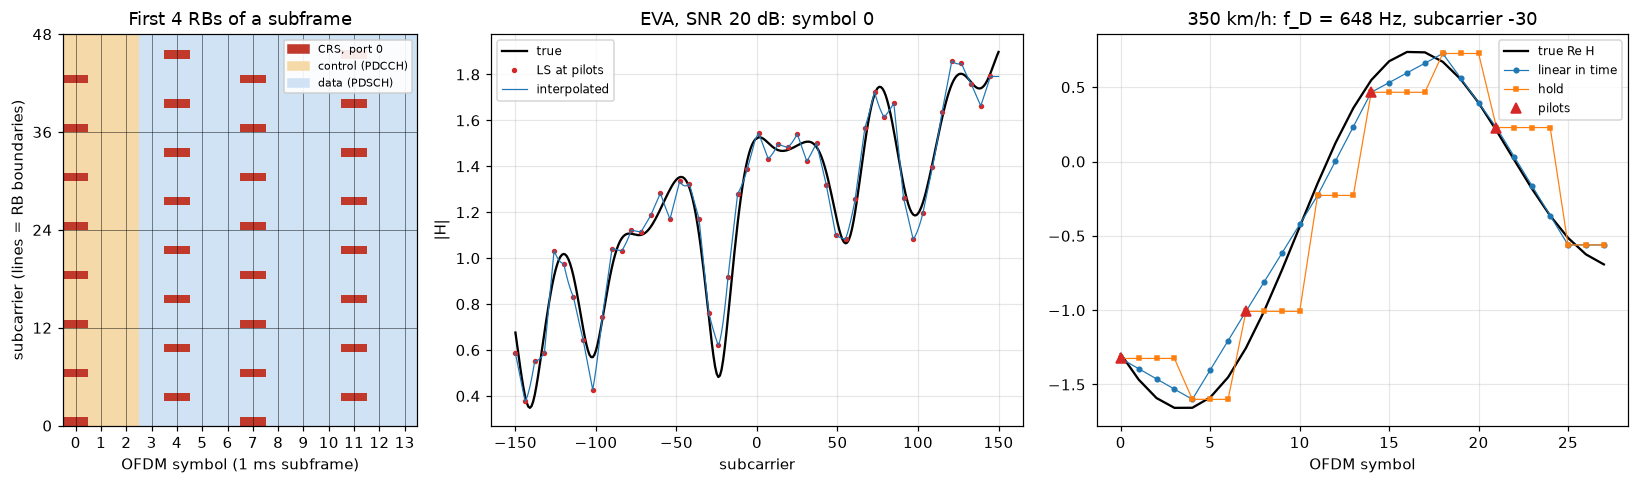

Channel estimation MSE, dB (pilot noise N0 = -20 dB):
     |    3 km/h lin  hold |  120 km/h lin  hold |  350 km/h lin  hold 


EPA  |       -23.1  -21.7 |       -22.1  -16.8 |       -17.4   -9.4 


EVA  |       -22.7  -21.3 |       -21.8  -16.6 |       -17.7   -9.6 


ETU  |       -17.8  -16.9 |       -17.2  -14.4 |       -15.2   -8.8 


In [6]:
M, V = crs_grid(14)
fig, ax = plt.subplots(1, 3, figsize=(15, 4.5), gridspec_kw={"width_ratios": [0.8, 1.2, 1.2]})
G = np.zeros((14, N_SC)); G[:3] = 1; G[M] = 2
ax[0].imshow(G[:, :48].T, origin="lower", aspect="auto", cmap=plt.matplotlib.colors.ListedColormap(["#cfe3f5", "#f5d9a8", "#c0392b"]),
             extent=[-0.5, 13.5, -0.5, 47.5])
ax[0].set_xticks(range(14)); ax[0].set_yticks(np.arange(0, 49, 12) - 0.5, [str(v) for v in range(0, 49, 12)])
ax[0].grid(True, color="k", lw=0.6, alpha=0.5)
ax[0].legend(handles=[plt.matplotlib.patches.Patch(color=c, label=l) for c, l in
                      [("#c0392b", "CRS, port 0"), ("#f5d9a8", "control (PDCCH)"), ("#cfe3f5", "data (PDSCH)")]],
             loc="upper right", fontsize=7, framealpha=0.9)
ax[0].set_xlabel("OFDM symbol (1 ms subframe)"); ax[0].set_ylabel("subcarrier (lines = RB boundaries)"); ax[0].set_title("First 4 RBs of a subframe")

q4 = QAM(2)
fd = SPEED_KMH / 3.6 * FC_GHZ * 1e9 / 3e8
n0 = 10 ** (-SNR_DB / 10)
nsym = 28
M2, V2 = crs_grid(nsym)
def run_subframes(name, fd, B, nsym=nsym, rng=rng):
    X = np.where(M2, V2, q4.mod(rng.integers(0, 2, (B, nsym, 2 * N_SC))))
    x = ofdm_mod(X); g = fading(name, x.shape[-1], fd, rng, (B,)); d = tap_delays(name)
    Y = ofdm_demod(apply_channel(x, g, d) + awgn(x.shape, n0, rng), nsym)
    Ht = freq_response(g[:, sym_starts(nsym) + N_FFT // 2], d)     # true H at the middle of each symbol
    return X, Y, Ht

X, Y, Ht = run_subframes(PROFILE, fd, 1, rng=np.random.default_rng(7))
He = chan_est(Y, V2, M2)
s = 0; kk = np.nonzero(M2[s])[0]
ax[1].plot(SC_IDX, np.abs(Ht[0, s]), "k", lw=1.5, label="true")
ax[1].plot(SC_IDX[kk], np.abs(Y[0, s, kk] / V2[s, kk]), "C3.", ms=5, label="LS at pilots")
ax[1].plot(SC_IDX, np.abs(He[0, s]), "C0", lw=0.8, label="interpolated")
ax[1].set_xlabel("subcarrier"); ax[1].set_ylabel("|H|"); ax[1].legend(fontsize=8)
ax[1].set_title(f"{PROFILE}, SNR {SNR_DB} dB: symbol 0")

Xf, Yf, Htf = run_subframes(PROFILE, 350 / 3.6 * FC_GHZ * 1e9 / 3e8, 1, rng=np.random.default_rng(8))
k0 = np.nonzero(M2[0])[0][20]
ps = np.nonzero(M2[:, k0])[0]
ax[2].plot(np.arange(nsym), Htf[0, :, k0].real, "k", lw=1.5, label="true Re H")
ax[2].plot(np.arange(nsym), chan_est(Yf, V2, M2)[0, :, k0].real, "C0o-", ms=3, lw=0.8, label="linear in time")
ax[2].plot(np.arange(nsym), chan_est(Yf, V2, M2, "hold")[0, :, k0].real, "C1s-", ms=3, lw=0.8, label="hold")
ax[2].plot(ps, (Yf[0, ps, k0] / V2[ps, k0]).real, "C3^", ms=7, label="pilots")
ax[2].set_xlabel("OFDM symbol"); ax[2].legend(fontsize=8)
ax[2].set_title(f"350 km/h: f_D = {350/3.6*FC_GHZ*1e9/3e8:.0f} Hz, subcarrier {SC_IDX[k0]}")
plt.tight_layout(); plt.show()

print(f"Channel estimation MSE, dB (pilot noise N0 = {10*np.log10(n0):.0f} dB):")
print(f"{'':5}" + "".join(f"| {v:>4} km/h lin  hold " for v in (3, 120, 350)))
for name in PROFILES:
    line = f"{name:5}"
    for v in (3, 120, 350):
        _, Yb, Htb = run_subframes(name, v / 3.6 * FC_GHZ * 1e9 / 3e8, 30)
        e = [10 * np.log10(np.mean(np.abs(chan_est(Yb, V2, M2, m) - Htb)**2)) for m in ("linear", "hold")]
        line += f"|      {e[0]:6.1f} {e[1]:6.1f} "
    print(line)

## 5. Doppler: subcarriers stop being orthogonal
If the channel changes within one symbol $T_u$, it is no longer a constant multiplier over the FFT window, and each subcarrier leaks into its neighbours. For the Jakes model (uniform arrival angles), the ICI power relative to the signal is:
$$P_\text{ICI}=1-\frac1{N^2}\sum_{n,m}J_0\!\big(2\pi f_D T_u\,\tfrac{n-m}{N}\big)\approx\frac{(\pi f_DT_u)^2}{6}$$
This is where 15 kHz comes from: the subcarrier must be wider than the Doppler **with margin** (ICI) and narrower than the coherence bandwidth (flat channel). At 2 GHz and 350 km/h, $f_DT_u\approx0.04$ and ICI ≈ −25 dB. That doesn't limit QPSK/16QAM; channel tracking from section 4 is the real limit.

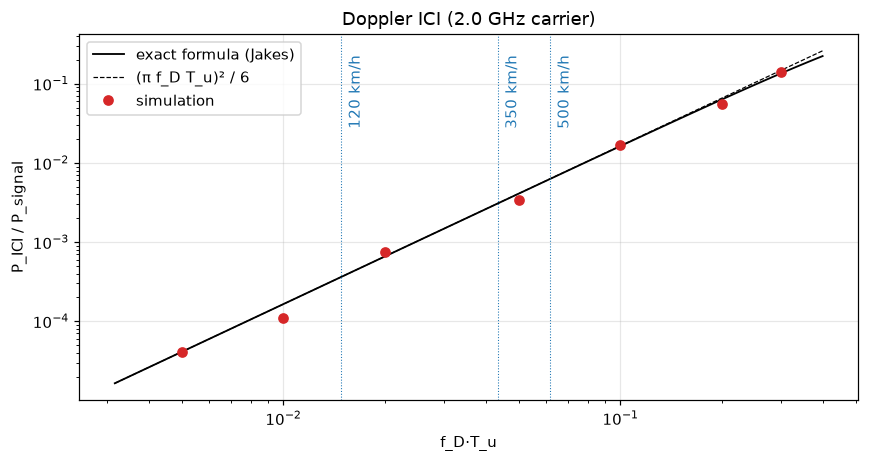

f_D·T_u = 0.005 (f_D =     75 Hz): ICI measured  -43.9 dB, theory  -43.9 dB
f_D·T_u = 0.010 (f_D =    150 Hz): ICI measured  -39.6 dB, theory  -37.8 dB
f_D·T_u = 0.020 (f_D =    300 Hz): ICI measured  -31.3 dB, theory  -31.8 dB
f_D·T_u = 0.050 (f_D =    750 Hz): ICI measured  -24.6 dB, theory  -23.9 dB
f_D·T_u = 0.100 (f_D =   1500 Hz): ICI measured  -17.8 dB, theory  -17.9 dB
f_D·T_u = 0.200 (f_D =   3000 Hz): ICI measured  -12.5 dB, theory  -12.0 dB
f_D·T_u = 0.300 (f_D =   4500 Hz): ICI measured   -8.5 dB, theory   -8.7 dB


In [7]:
def ici_theory(fdT):
    n = np.arange(-N_FFT + 1, N_FFT)
    return 1 - np.sum((N_FFT - np.abs(n)) / N_FFT**2 * j0(2 * np.pi * fdT * n / N_FFT))

fdTs = np.array([0.005, 0.01, 0.02, 0.05, 0.1, 0.2, 0.3])
meas = []
for fdT in fdTs:
    B = 30
    X = q4.mod(rng.integers(0, 2, (B, 14, 2 * N_SC))); x = ofdm_mod(X)
    g = fading("EPA", x.shape[-1], fdT / T_U, rng, (B,), n_sin=32); d = tap_delays("EPA")
    Y = ofdm_demod(apply_channel(x, g, d), 14)
    Hm = np.stack([freq_response(g[:, p:p + N_FFT].mean(1), d) for p in sym_starts(14)], 1)   # the "useful" part
    meas.append(np.mean(np.abs(Y - Hm * X)**2))
fg = np.logspace(-2.5, -0.4, 100)
fig, a = plt.subplots(figsize=(8, 4.3))
a.loglog(fg, [ici_theory(v) for v in fg], "k", lw=1.2, label="exact formula (Jakes)")
a.loglog(fg, (np.pi * fg)**2 / 6, "k--", lw=0.8, label="(π f_D T_u)² / 6")
a.loglog(fdTs, meas, "C3o", label="simulation")
for v in (120, 350, 500):
    fv = v / 3.6 * FC_GHZ * 1e9 / 3e8 * T_U
    a.axvline(fv, color="C0", lw=0.7, ls=":"); a.text(fv * 1.05, 3e-2, f"{v} km/h", color="C0", rotation=90)
a.set_xlabel("f_D·T_u"); a.set_ylabel("P_ICI / P_signal"); a.legend(); a.set_title(f"Doppler ICI ({FC_GHZ} GHz carrier)")
plt.tight_layout(); plt.show()
for fdT, m in zip(fdTs, meas):
    print(f"f_D·T_u = {fdT:5.3f} (f_D = {fdT/T_U:6.0f} Hz): ICI measured {10*np.log10(m):6.1f} dB, theory {10*np.log10(ici_theory(fdT)):6.1f} dB")

## 6. Modulation and uncoded BER: AWGN vs. fading
LTE adapts the modulation to the channel: QPSK / 16QAM / 64QAM (and 256QAM from Rel-12), i.e. 2/4/6 bits per resource element. In AWGN the BER falls exponentially with SNR. On a subcarrier with Rayleigh fading, the instantaneous SNR $\gamma$ is exponentially distributed, and the average is
$$\overline{P_b}=\int_0^\infty P_b^\text{AWGN}(\gamma)\,\frac{e^{-\gamma/\bar\gamma}}{\bar\gamma}\,d\gamma\;\propto\;\frac1{\bar\gamma}$$
Every 10 dB buys only one order of magnitude. The BER is dominated by subcarriers sitting in a deep fade. The equalizer can't help them: the noise gets divided by $|H_k|^2\approx0$. Below: perfect channel knowledge, $H_k$ from the `PROFILE` model in the time domain (the full OFDM chain).

64QAM, BER = 1e-3: AWGN 22.5 dB, Rayleigh 37.8 dB — fading costs 15 dB, and every further 10 dB buys only one order of magnitude


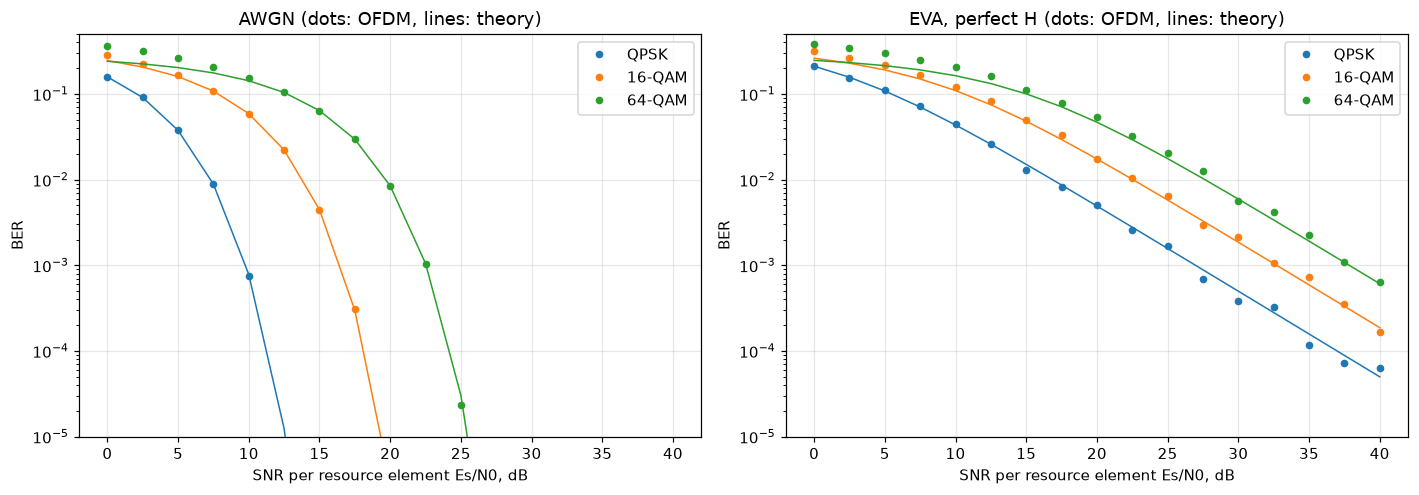

In [8]:
snrs = np.arange(0, 41, 2.5)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
B, nsym = 300, 2                     # many independent channel realizations, 2 symbols each
for i, Q in enumerate((2, 4, 6)):
    q = QAM(Q); ra, rf = [], []
    for snr in snrs:
        n0 = 10 ** (-snr / 10)
        bits = rng.integers(0, 2, (B, nsym, Q * N_SC)); X = q.mod(bits); x = ofdm_mod(X)
        Y = ofdm_demod(x + awgn(x.shape, n0, rng), nsym)
        ra.append(np.mean(q.hard(Y) != bits))
        g = fading(PROFILE, 1, 0, rng, (B,)); d = tap_delays(PROFILE)
        Y = ofdm_demod(apply_channel(x, g, d) + awgn(x.shape, n0, rng), nsym)
        rf.append(np.mean(q.hard(Y / freq_response(g, d)) != bits))
    g = 10 ** (snrs / 10)
    ax[0].semilogy(snrs, ber_awgn(Q, g), f"C{i}-", lw=1); ax[0].semilogy(snrs, ra, f"C{i}o", ms=4, label=f"{2**Q}-QAM" if Q > 2 else "QPSK")
    ax[1].semilogy(snrs, ber_rayleigh(Q, g), f"C{i}-", lw=1); ax[1].semilogy(snrs, rf, f"C{i}o", ms=4, label=f"{2**Q}-QAM" if Q > 2 else "QPSK")
    if Q == 6:
        thr = lambda f: brentq(lambda s: np.log10(np.maximum(f(10**(s / 10)), 1e-300)) + 3, 0, 50)
        print(f"64QAM, BER = 1e-3: AWGN {thr(lambda g: ber_awgn(6, g)):.1f} dB, Rayleigh {thr(lambda g: ber_rayleigh(6, g)):.1f} dB "
              "— fading costs 15 dB, and every further 10 dB buys only one order of magnitude")
for a, t in zip(ax, ["AWGN", f"{PROFILE}, perfect H"]):
    a.set_ylim(1e-5, 0.5); a.set_xlabel("SNR per resource element Es/N0, dB"); a.set_ylabel("BER"); a.legend(); a.set_title(t + " (dots: OFDM, lines: theory)")
plt.tight_layout(); plt.show()

## 7. The LTE turbo code
Two identical **recursive** convolutional encoders (RSC, 8 states, $G=[1,\ 15_8/13_8]$). The first sees the bits in order, the second sees them permuted by the QPP interleaver $\Pi(i)=(f_1i+f_2i^2)\bmod K$. The output is systematic bits plus two parity streams, $R=1/3$, plus 12 tail bits that return both encoders to the zero state. Recursion matters: a single one at the input produces an infinite response, so low-weight codewords only appear if the interleaver "unluckily" lines up low weights in both encoders, and QPP makes that rare.

The decoder follows the same idea as BP in LDPC, but with only two nodes. Each **BCJR** (MAP on the trellis, forward–backward pass) takes the channel LLRs and a-priori information from the other decoder, and passes on only the **extrinsic** part
$$L_e=L_\text{post}-L_\text{ch}-L_a,$$
so it never hands its partner back the partner's own information. **log-MAP** computes $\max^*(a,b)=\max(a,b)+\ln(1+e^{-|a-b|})$ exactly. **max-log-MAP** drops the correction term (hardware likes that) and loses a few tenths of a dB; a scale of 0.7 on $L_e$ recovers part of it, analogous to the normalization in min-sum.

Left: the waterfall in AWGN (BPSK) for $K$ = `K_TURBO`; the dashed line is the binary-input Shannon limit at $R=1/3$. Right: BER after each log-MAP iteration.

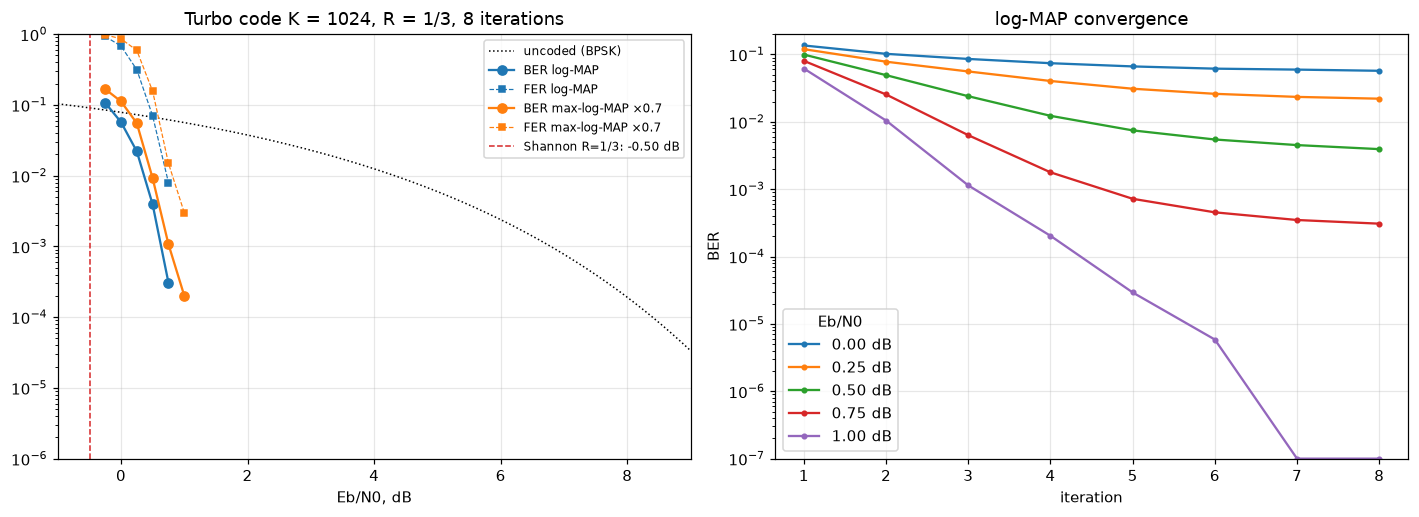

 Eb/N0 | BER log-MAP  FER  | BER max-log  FER  | frames
 -0.25 |  1.1e-01  0.930 |  1.7e-01   0.980 | 100/100
  0.00 |  5.7e-02  0.680 |  1.1e-01   0.860 | 100/100
  0.25 |  2.2e-02  0.315 |  5.5e-02   0.590 | 200/100
  0.50 |  3.9e-03  0.070 |  9.2e-03   0.157 | 700/300
  0.75 |  3.1e-04  0.008 |  1.1e-03   0.015 | 1000/1000
  1.00 |  0.0e+00  0.000 |  2.0e-04   0.003 | 1000/1000
  1.25 |  0.0e+00  0.000 |  0.0e+00   0.000 | 1000/1000


In [9]:
def biawgn_limit(R):
    """Eb/N0 (dB) at which the BPSK-AWGN capacity equals R."""
    def cap(ebn0_db):
        s2 = 1 / (2 * R * 10 ** (ebn0_db / 10)); mu = 2 / s2
        f = lambda l: np.log2(1 + np.exp(-l)) * np.exp(-(l - mu)**2 / (4 * mu)) / np.sqrt(4 * np.pi * mu)
        return 1 - quad(f, mu - 40 * np.sqrt(mu), mu + 40 * np.sqrt(mu))[0]
    return brentq(lambda e: cap(e) - R, -2, 5)

def simulate_turbo(ebn0_list, K, exact, punct=None, min_fe=40, max_frames=2000, batch=100, track=False):
    res, it_ber = [], []
    for e in ebn0_list:
        be = fe = nf = 0; per_it = np.zeros(TURBO_ITERS)
        while fe < min_fe and nf < max_frames:
            u = rng.integers(0, 2, (batch, K)); c = turbo_encode(u)
            m = np.ones(c.shape[1], bool) if punct is None else punct
            R = K / m.sum(); s2 = 1 / (2 * R * 10 ** (e / 10))
            L = np.zeros(c.shape); L[:, m] = 2 * ((1 - 2 * c[:, m]) + np.sqrt(s2) * rng.standard_normal((batch, m.sum()))) / s2
            def cb(it, Lp): per_it[it] += np.sum((Lp < 0) != u)
            uh = turbo_decode(L, K, exact=exact, cb=cb if track else None)
            err = uh != u; be += err.sum(); fe += err.any(1).sum(); nf += batch
        res.append((be / (nf * K), fe / nf, nf)); it_ber.append(per_it / (nf * K))
    return np.array(res), np.array(it_ber)

ebn0 = np.arange(-0.25, 1.26, 0.25)
r_log, it_log = simulate_turbo(ebn0, K_TURBO, True, track=True, max_frames=1000)
r_max, _ = simulate_turbo(ebn0, K_TURBO, False, max_frames=1000)
R3 = K_TURBO / (3 * K_TURBO + 12)
lim3 = biawgn_limit(1 / 3)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
eg = np.linspace(-1, 9, 200)
ax[0].semilogy(eg, 0.5 * erfc(np.sqrt(10 ** (eg / 10))), "k:", lw=1, label="uncoded (BPSK)")
for r, lab, c in [(r_log, "log-MAP", "C0"), (r_max, "max-log-MAP ×0.7", "C1")]:
    ok = r[:, 0] > 0
    ax[0].semilogy(ebn0[ok], r[ok, 0], c + "o-", label=f"BER {lab}")
    ax[0].semilogy(ebn0[r[:, 1] > 0], r[r[:, 1] > 0, 1], c + "s--", ms=4, lw=0.8, label=f"FER {lab}")
ax[0].axvline(lim3, color="C3", ls="--", lw=1, label=f"Shannon R=1/3: {lim3:.2f} dB")
ax[0].set_xlim(-1, 9); ax[0].set_ylim(1e-6, 1); ax[0].set_xlabel("Eb/N0, dB"); ax[0].legend(fontsize=8)
ax[0].set_title(f"Turbo code K = {K_TURBO}, R = 1/3, {TURBO_ITERS} iterations")
for j, e in enumerate(ebn0):
    if 0 <= e <= 1.0:
        ax[1].semilogy(np.arange(1, TURBO_ITERS + 1), np.maximum(it_log[j], 1e-7), "o-", ms=3, label=f"{e:.2f} dB")
ax[1].set_xlabel("iteration"); ax[1].set_ylabel("BER"); ax[1].set_ylim(1e-7, 0.2); ax[1].legend(title="Eb/N0")
ax[1].set_title("log-MAP convergence")
plt.tight_layout(); plt.show()

print(" Eb/N0 | BER log-MAP  FER  | BER max-log  FER  | frames")
for e, a, b in zip(ebn0, r_log, r_max):
    print(f" {e:5.2f} |  {a[0]:.1e}  {a[1]:.3f} |  {b[0]:.1e}   {b[1]:.3f} | {int(a[2])}/{int(b[2])}")

### Turbo vs. LDPC at the same $R$ and $n$
To compare with the regular (3,6) LDPC code from the LDPC notebook ($R=1/2$, $n=1008$, BER $10^{-4}$ at ≈2.3 dB), we take $K=512$ and puncture half of the parity bits: $n=1036$, $R\approx1/2$.

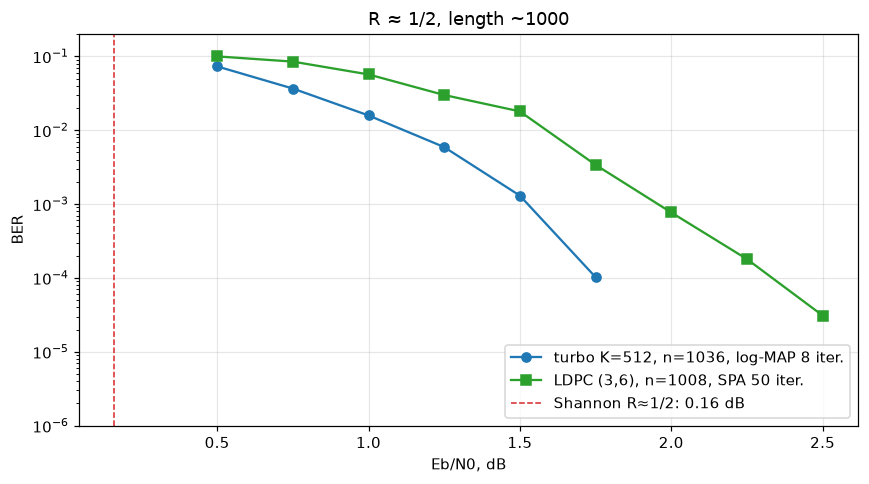

Eb/N0 0.50 dB: turbo BER 7.3e-02 FER 0.750 (200 frames) | LDPC (3,6) BER 1.0e-01
Eb/N0 0.75 dB: turbo BER 3.7e-02 FER 0.475 (200 frames) | LDPC (3,6) BER 8.5e-02
Eb/N0 1.00 dB: turbo BER 1.6e-02 FER 0.220 (200 frames) | LDPC (3,6) BER 5.7e-02
Eb/N0 1.25 dB: turbo BER 5.9e-03 FER 0.090 (600 frames) | LDPC (3,6) BER 3.0e-02
Eb/N0 1.50 dB: turbo BER 1.3e-03 FER 0.022 (1800 frames) | LDPC (3,6) BER 1.8e-02
Eb/N0 1.75 dB: turbo BER 1.0e-04 FER 0.003 (2000 frames) | LDPC (3,6) BER 3.4e-03
Eb/N0 2.00 dB: turbo BER 0.0e+00 FER 0.000 (2000 frames) | LDPC (3,6) BER 7.7e-04


In [10]:
K2 = 512
pm = puncture_half(K2)
ebn0_2 = np.arange(0.5, 2.01, 0.25)
r_p, _ = simulate_turbo(ebn0_2, K2, True, punct=pm, batch=200, max_frames=2000)
ldpc = {0.5: 1.0e-01, 0.75: 8.5e-02, 1.0: 5.7e-02, 1.25: 3.0e-02, 1.5: 1.8e-02, 1.75: 3.4e-03,
        2.0: 7.7e-04, 2.25: 1.8e-04, 2.5: 3.1e-05}         # SPA, 50 iterations; table from ldpc_sim.ipynb
lim2 = biawgn_limit(K2 / pm.sum())
fig, a = plt.subplots(figsize=(8, 4.5))
ok = r_p[:, 0] > 0
a.semilogy(ebn0_2[ok], r_p[ok, 0], "C0o-", label=f"turbo K={K2}, n={pm.sum()}, log-MAP {TURBO_ITERS} iter.")
a.semilogy(list(ldpc), list(ldpc.values()), "C2s-", label="LDPC (3,6), n=1008, SPA 50 iter.")
a.axvline(lim2, color="C3", ls="--", lw=1, label=f"Shannon R≈1/2: {lim2:.2f} dB")
a.set_xlabel("Eb/N0, dB"); a.set_ylabel("BER"); a.set_ylim(1e-6, 0.2); a.legend(); a.set_title("R ≈ 1/2, length ~1000")
plt.tight_layout(); plt.show()
for e, r in zip(ebn0_2, r_p):
    print(f"Eb/N0 {e:.2f} dB: turbo BER {r[0]:.1e} FER {r[1]:.3f} ({int(r[2])} frames) | LDPC (3,6) BER {ldpc.get(e, float('nan')):.1e}")

## 8. Code + OFDM: frequency diversity
The key trick of the LTE downlink: a codeword is spread across the **whole band** (frequency first, then time). Subcarriers in fades give LLR ≈ 0, which the decoder treats as erasures and recovers from the parity on subcarriers that are in good shape. If instead the block sits in a narrow band $\ll B_c$ (2 RBs = 360 kHz), all its symbols fade **together**, and no code can save a frame that lands in a fade: the slope goes back to $1/\bar\gamma$, as without coding.

The diversity order is roughly the number of independently fading chunks of the band, $\sim N_\text{SC}\Delta f/B_c$. QPSK, $K$ = `K_TURBO`, $R=1/3$, the `PROFILE` channel is static over a block, perfect knowledge of $H$, max-log-MAP decoder.

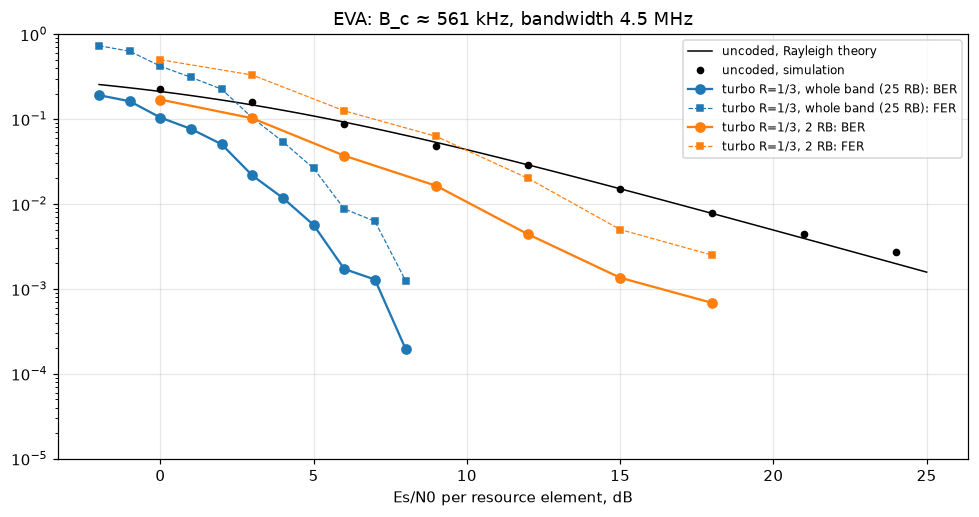

whole band (25 RB)   SNR  -2 dB: BER 1.9e-01  FER 0.730
whole band (25 RB)   SNR  -1 dB: BER 1.6e-01  FER 0.630
whole band (25 RB)   SNR   0 dB: BER 1.0e-01  FER 0.420
whole band (25 RB)   SNR   1 dB: BER 7.7e-02  FER 0.310
whole band (25 RB)   SNR   2 dB: BER 5.0e-02  FER 0.225
whole band (25 RB)   SNR   3 dB: BER 2.2e-02  FER 0.103
whole band (25 RB)   SNR   4 dB: BER 1.2e-02  FER 0.054
whole band (25 RB)   SNR   5 dB: BER 5.7e-03  FER 0.026
whole band (25 RB)   SNR   6 dB: BER 1.7e-03  FER 0.009
whole band (25 RB)   SNR   7 dB: BER 1.3e-03  FER 0.006
whole band (25 RB)   SNR   8 dB: BER 2.0e-04  FER 0.001

2 RB                 SNR   0 dB: BER 1.7e-01  FER 0.500
2 RB                 SNR   3 dB: BER 1.0e-01  FER 0.330
2 RB                 SNR   6 dB: BER 3.7e-02  FER 0.125
2 RB                 SNR   9 dB: BER 1.6e-02  FER 0.062
2 RB                 SNR  12 dB: BER 4.4e-03  FER 0.020
2 RB                 SNR  15 dB: BER 1.4e-03  FER 0.005
2 RB                 SNR  18 dB: BER 6.8e-04  F

In [11]:
def coded_ofdm_batch(snr_db, nsc, B, name=PROFILE, K=K_TURBO):
    u = rng.integers(0, 2, (B, K)); c = turbo_encode(u)
    perm = rng.permutation(c.shape[1])                           # channel interleaver
    s = q4.mod(c[:, perm]); nre = s.shape[1]; nsym = -(-nre // nsc)
    H = freq_response(fading(name, 1, 0, rng, (B,))[:, 0], tap_delays(name))
    k0 = rng.integers(0, N_SC - nsc + 1, B)
    Hk = np.stack([np.tile(H[b, k0[b]:k0[b] + nsc], nsym)[:nre] for b in range(B)])   # frequency first
    n0 = 10 ** (-snr_db / 10)
    y = Hk * s + awgn(s.shape, n0, rng)
    z = y / Hk
    L = np.empty(c.shape); L[:, perm] = q4.llr(z, n0 / np.abs(Hk)**2)
    uh = turbo_decode(L, K, exact=False)                          # max-log: the shape of the curve matters here, not tenths of a dB
    return (uh != u).sum(), (uh != u).any(1).sum(), (q4.hard(z) != c[:, perm]).mean()

def coded_ofdm(snr_db, nsc, min_fe=25, max_frames=800, batch=100):
    be = fe = nf = 0; unc = []
    while fe < min_fe and nf < max_frames:
        b, f, uc = coded_ofdm_batch(snr_db, nsc, batch); be += b; fe += f; nf += batch; unc.append(uc)
    return be / (nf * K_TURBO), fe / nf, np.mean(unc)

allocs = {f"whole band ({N_RB} RB)": (N_SC, np.arange(-2, 9, 1)), "2 RB": (24, np.arange(0, 25, 3))}
res8 = {k: np.array([coded_ofdm(s, n) for s in sn]) for k, (n, sn) in allocs.items()}
fig, a = plt.subplots(figsize=(9, 4.8))
sg = np.arange(-2, 25.1, 0.5)
sn2 = allocs["2 RB"][1]
a.semilogy(sg, ber_rayleigh(2, 10 ** (sg / 10)), "k-", lw=1, label="uncoded, Rayleigh theory")
a.semilogy(sn2, res8["2 RB"][:, 2], "ko", ms=4, label="uncoded, simulation")
for i, (k, r) in enumerate(res8.items()):
    sn = allocs[k][1]
    ok = r[:, 0] > 0
    a.semilogy(sn[ok], r[ok, 0], f"C{i}o-", label=f"turbo R=1/3, {k}: BER")
    ok = r[:, 1] > 0
    a.semilogy(sn[ok], r[ok, 1], f"C{i}s--", ms=4, lw=0.8, label=f"turbo R=1/3, {k}: FER")
a.set_ylim(1e-5, 1); a.set_xlabel("Es/N0 per resource element, dB"); a.legend(fontsize=8)
a.set_title(f"{PROFILE}: B_c ≈ {1/(5*tau_rms(PROFILE))/1e3:.0f} kHz, bandwidth {N_SC*DF/1e6:.1f} MHz")
plt.tight_layout(); plt.show()
for k, r in res8.items():
    sn = allocs[k][1]
    for e, rr in zip(sn, r):
        print(f"{k:20} SNR {e:3d} dB: BER {rr[0]:.1e}  FER {rr[1]:.3f}")
    print()

## 9. PAPR: why the uplink isn't plain OFDM
By the central limit theorem, a sum of hundreds of subcarriers with random phases is a complex Gaussian process. $|x|^2$ is exponential, and the peak-to-average power ratio $\text{PAPR}=\max|x|^2/\overline{|x|^2}$ is large. For $N$ independent samples
$$P(\text{PAPR}>z)\approx1-\big(1-e^{-z}\big)^{N}$$
The curve assumes $N$ independent samples. With oversampling there are extra peaks between them, so the measured OFDM curve sits ~0.5 dB to the right.

The phone's power amplifier has to stay linear at the peaks. That means a large back-off, low efficiency and a drained battery. So the LTE uplink uses **SC-FDMA**: before the IFFT the symbols go through a DFT of size $M$ (DFT-spread OFDM). The signal keeps the CP and the frequency-domain equalizer, but its envelope behaves like single-carrier QPSK. Measured with 4× oversampling (otherwise the peaks between samples are missed).

OFDM, QPSK     : PAPR exceeded by 0.1 % of symbols: 11.3 dB


OFDM, 64QAM    : PAPR exceeded by 0.1 % of symbols: 11.4 dB
SC-FDMA, QPSK  : PAPR exceeded by 0.1 % of symbols: 8.1 dB


SC-FDMA, 16QAM : PAPR exceeded by 0.1 % of symbols: 9.2 dB


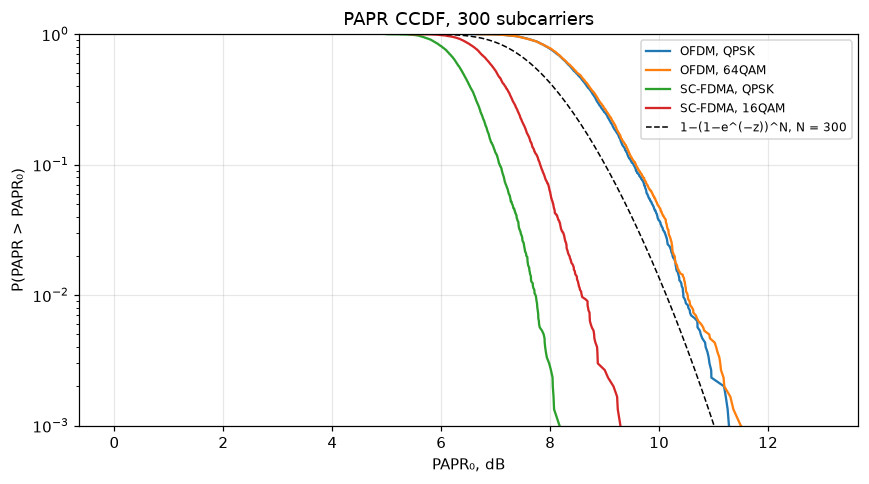

In [12]:
OS, Mu, B = 4, N_SC, 3000
def papr(X, os=OS):
    G = np.zeros((len(X), N_FFT * os), complex); G[:, SC_IDX % (N_FFT * os)] = X
    x = np.fft.ifft(G, axis=1)
    p = np.abs(x)**2
    return 10 * np.log10(p.max(1) / p.mean(1))
fig, a = plt.subplots(figsize=(8, 4.5))
zz = np.linspace(0, 13, 200)
cases = {"OFDM, QPSK": QAM(2).mod(rng.integers(0, 2, (B, 2 * Mu))),
         "OFDM, 64QAM": QAM(6).mod(rng.integers(0, 2, (B, 6 * Mu))),
         "SC-FDMA, QPSK": np.fft.fft(QAM(2).mod(rng.integers(0, 2, (B, 2 * Mu))), axis=1) / np.sqrt(Mu),
         "SC-FDMA, 16QAM": np.fft.fft(QAM(4).mod(rng.integers(0, 2, (B, 4 * Mu))), axis=1) / np.sqrt(Mu)}
for i, (k, X) in enumerate(cases.items()):
    p = np.sort(papr(X))
    a.semilogy(p, 1 - np.arange(B) / B, f"C{i}", lw=1.5, label=k)
    print(f"{k:15}: PAPR exceeded by 0.1 % of symbols: {np.quantile(p, 0.999):.1f} dB")
a.semilogy(zz, 1 - (1 - np.exp(-10 ** (zz / 10)))**N_SC, "k--", lw=1, label=f"1−(1−e^(−z))^N, N = {N_SC}")
a.set_ylim(1e-3, 1); a.set_xlabel("PAPR₀, dB"); a.set_ylabel("P(PAPR > PAPR₀)"); a.legend(fontsize=8)
a.set_title(f"PAPR CCDF, {N_SC} subcarriers")
plt.tight_layout(); plt.show()

## Comparison with CDMA and LDPC
3G (WCDMA) and 4G (LTE) solve the same problem, a wide band over a multipath channel, from opposite ends.

| | CDMA / WCDMA | OFDM / LTE |
|---|---|---|
| Multipath | RAKE: each path is a separate "finger", combined coherently | CP + one division per subcarrier |
| Equalizer complexity | grows with the number of paths and the bandwidth | FFT: $O(N\log N)$, independent of the channel |
| Diversity | paths in the RAKE (time) | code across subcarriers (frequency) |
| Multiple access | codes, everyone in one band, near–far problem, fast power control | resource blocks, orthogonal within a cell |
| Peak-to-average ratio | low | high → SC-FDMA on the uplink |
| Frequency sensitivity | weak | Doppler / frequency offset → ICI, needs precise synchronization |

Coding: LTE uses a turbo code (two convolutional codes + QPP); 5G NR uses a quasi-cyclic LDPC code for data. Both exchange **extrinsic** LLRs iteratively. At $n\approx1000$ and $R=1/2$, the turbo code here beats the regular (3,6) LDPC code. The regular code has a poor threshold (1.1 dB vs. 0.2 dB for Shannon), while the 8-state turbo code is close to an irregular optimum. LDPC won in 5G less on short blocks and more because its decoder is **parallel** (BCJR is sequential along the trellis) and because it has no noticeable error floor at high code rates and long block lengths.

## Things to try
- `PROFILE = "ETU"`: in section 8 the diversity is even larger (steeper curve), but in section 4 linear interpolation in frequency hits a ~−18 dB MSE floor. At high SNR you need MMSE interpolation based on the channel correlation
- `SPEED_KMH = 500`, `FC_GHZ = 3.5`: in section 4 (right) linear interpolation between pilots still tracks the channel; ICI from section 5 rises toward −17 dB, which is already an SINR ceiling for 64QAM
- `K_TURBO = 6144`: a steeper waterfall, closer to Shannon (takes ~6× longer to run); `K_TURBO = 40`: no waterfall, a gentle curve like a plain convolutional code
- `TURBO_ITERS = 2`: shows how much the iterations give; in section 7 (right) the BER after the 1st iteration is close to that of a convolutional code
- `BW_MHZ = 1.4`: in section 8 the "whole band" is 6 RBs, there is less diversity, and the curve slides toward 2 RB
- in section 9, add 64QAM via SC-FDMA to `cases`: PAPR grows with the peak factor of the constellation itself but stays below OFDM